# Cancer du sein – Modèle de prédiction du risque de décès

**Objectif :** prédire le statut d'une patiente (*Alive* / *Dead*) à partir de son profil clinique, puis produire un **score de risque** par patiente, à importer dans Power BI (page 2 du dashboard).

**Données :** SEER Breast Cancer (Kaggle) – patientes diagnostiquées entre 2006 et 2010.

**Plan :**
1. Chargement et nettoyage
2. Préparation des variables
3. Entraînement de deux modèles (régression logistique, random forest)
4. Évaluation (précision, rappel, AUC, matrice de confusion)
5. Importance des variables
6. Export des résultats pour Power BI

> ⚠️ Outil d'analyse uniquement : un modèle statistique ne remplace pas un avis médical.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

## 1. Chargement et nettoyage

In [2]:
df = pd.read_csv("Breast_Cancer.csv")
df.columns = df.columns.str.strip()          # 'T Stage ' contient un espace en trop
print("Lignes avant nettoyage :", len(df))

df = df.drop_duplicates().reset_index(drop=True)
print("Lignes après suppression des doublons :", len(df))

df["Patient_ID"] = np.arange(1, len(df) + 1)  # identifiant pour relier les résultats dans Power BI
df.head()

Lignes avant nettoyage : 4024
Lignes après suppression des doublons : 4023


,Age,Race,Marital Status,T Stage,N Stage,6th Stage,differentiate,Grade,A Stage,Tumor Size,Estrogen Status,Progesterone Status,Regional Node Examined,Reginol Node Positive,Survival Months,Status,Patient_ID
0,68,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,4,Positive,Positive,24,1,60,Alive,1
1,50,White,Married,T2,N2,IIIA,Moderately differentiated,2,Regional,35,Positive,Positive,14,5,62,Alive,2
2,58,White,Divorced,T3,N3,IIIC,Moderately differentiated,2,Regional,63,Positive,Positive,14,7,75,Alive,3
3,58,White,Married,T1,N1,IIA,Poorly differentiated,3,Regional,18,Positive,Positive,2,1,84,Alive,4
4,47,White,Married,T2,N1,IIB,Poorly differentiated,3,Regional,41,Positive,Positive,3,1,50,Alive,5


In [3]:
print(df.isna().sum().sum(), "valeur manquante")
df["Status"].value_counts(normalize=True).round(3)

0 valeur manquante


Status
Alive    0.847
Dead     0.153
Name: proportion, dtype: float64

Les classes sont **déséquilibrées** : environ 85 % de patientes en vie et 15 % de décès.
On en tiendra compte avec `class_weight="balanced"` et en regardant le **rappel** et l'**AUC**, pas seulement la précision globale.

## 2. Préparation des variables

- **Cible :** `Status` (1 = Dead, 0 = Alive)
- **On exclut `Survival Months`** : c'est une information connue *après* le suivi (les patientes décédées ont mécaniquement un suivi plus court). La garder fausserait le modèle (fuite de données).
- **On exclut `differentiate`** : c'est la même information que `Grade`, en texte.

In [4]:
df["Grade"] = df["Grade"].astype(str).str.strip().replace({"anaplastic; Grade IV": "4"})
y = (df["Status"] == "Dead").astype(int)

num_cols = ["Age", "Tumor Size", "Regional Node Examined", "Reginol Node Positive"]
cat_cols = ["Race", "Marital Status", "T Stage", "N Stage", "6th Stage", "Grade",
            "A Stage", "Estrogen Status", "Progesterone Status"]
X = df[num_cols + cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])
print("Entraînement :", X_train.shape, "– Test :", X_test.shape)

Entraînement : (3017, 13) – Test : (1006, 13)


## 3. Entraînement des modèles

In [5]:
models = {
    "Régression logistique": LogisticRegression(class_weight="balanced", max_iter=2000),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5,
                                            class_weight="balanced", random_state=RANDOM_STATE),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pipes, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv_auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "Modèle": name,
        "AUC (validation croisée)": cv_auc.mean(),
        "AUC (test)": roc_auc_score(y_test, proba),
        "Précision globale": accuracy_score(y_test, pred),
        "Précision (Dead)": precision_score(y_test, pred),
        "Rappel (Dead)": recall_score(y_test, pred),
        "F1 (Dead)": f1_score(y_test, pred),
    })
    pipes[name] = pipe

results = pd.DataFrame(rows).set_index("Modèle").round(3)
results

,AUC (validation croisée),AUC (test),Précision globale,Précision (Dead),Rappel (Dead),F1 (Dead)
Modèle,,,,,,
Régression logistique,0.742,0.736,0.702,0.284,0.623,0.390
Random forest,0.728,0.718,0.732,0.293,0.532,0.378


**Lecture :**
- **AUC** : capacité à classer une patiente à risque au-dessus d'une patiente non à risque (0,5 = hasard, 1 = parfait).
- **Rappel (Dead)** : part des décès réels que le modèle repère.
- **Précision (Dead)** : parmi les patientes signalées à risque, part réellement décédée.

Modèle retenu : Régression logistique


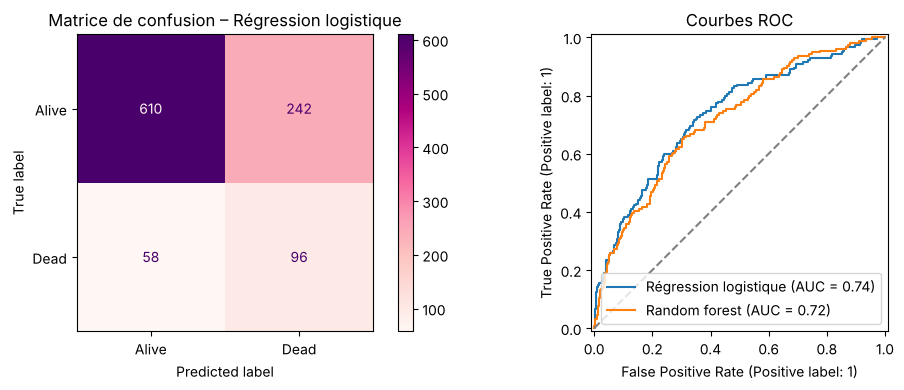

In [6]:
best_name = results["AUC (validation croisée)"].idxmax()
best = pipes[best_name]
print("Modèle retenu :", best_name)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_estimator(best, X_test, y_test, display_labels=["Alive", "Dead"],
                                      cmap="RdPu", ax=axes[0])
axes[0].set_title("Matrice de confusion – " + best_name)
for name, pipe in pipes.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("Courbes ROC")
plt.tight_layout()
plt.show()

## 5. Importance des variables

On mesure l'importance par **permutation** : on mélange une variable et on regarde de combien l'AUC baisse. Plus la baisse est forte, plus la variable compte.

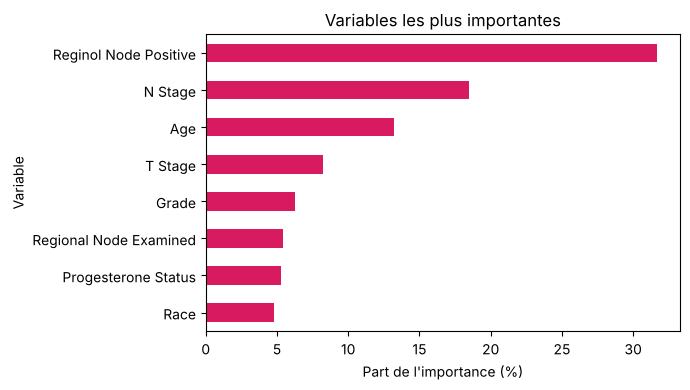

,Variable,Importance (%)
3,Reginol Node Positive,31.7
7,N Stage,18.5
0,Age,13.2
6,T Stage,8.2
9,Grade,6.3
2,Regional Node Examined,5.4
12,Progesterone Status,5.3
4,Race,4.8
8,6th Stage,3.5
5,Marital Status,2.4


In [7]:
perm = permutation_importance(best, X_test, y_test, scoring="roc_auc",
                              n_repeats=20, random_state=RANDOM_STATE)
importance = (pd.DataFrame({"Variable": X.columns, "Importance": perm.importances_mean})
              .sort_values("Importance", ascending=False))
importance["Importance"] = importance["Importance"].clip(lower=0)
importance["Importance (%)"] = (100 * importance["Importance"] / importance["Importance"].sum()).round(1)

importance.head(8).plot.barh(x="Variable", y="Importance (%)", color="#D81B60",
                            legend=False, figsize=(7, 4))
plt.gca().invert_yaxis()
plt.title("Variables les plus importantes")
plt.xlabel("Part de l'importance (%)")
plt.tight_layout()
plt.show()
importance[["Variable", "Importance (%)"]]

## 6. Score de risque et export pour Power BI

Pour éviter de noter une patiente avec un modèle qui l'a déjà vue, les scores sont calculés en **validation croisée** (chaque patiente est prédite par un modèle entraîné sans elle).

- **Score de risque** : probabilité de décès estimée, de 0 à 100
- **Niveau** : Faible (< 30), Modéré (30 à 60), Élevé (> 60)

Les fichiers sont exportés au format français (séparateur `;`, décimale `,`) pour que Power BI les lise correctement.

In [8]:
oof = cross_val_predict(best, X, y, cv=cv, method="predict_proba")[:, 1]
df["Score_Risque"] = (100 * oof).round().astype(int)
df["Niveau_Risque"] = pd.cut(df["Score_Risque"], bins=[-1, 29, 60, 100],
                             labels=["1 · Faible", "2 · Modéré", "3 · Élevé"])

print(df["Niveau_Risque"].value_counts().sort_index())
print()
print("Taux de décès réel par niveau :")
print(df.groupby("Niveau_Risque", observed=True)["Status"].apply(lambda s: (s == "Dead").mean()).round(3))

Niveau_Risque
1 · Faible    1201
2 · Modéré    1983
3 · Élevé      839
Name: count, dtype: int64

Taux de décès réel par niveau :
Niveau_Risque
1 · Faible    0.050
2 · Modéré    0.134
3 · Élevé     0.347
Name: Status, dtype: float64


In [9]:
export_cols = ["Patient_ID", "Age", "6th Stage", "Grade", "Tumor Size", "Reginol Node Positive",
               "Estrogen Status", "Progesterone Status", "Status", "Score_Risque", "Niveau_Risque"]
df[export_cols].to_csv("Scores_Risque.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")

importance[["Variable", "Importance (%)"]].to_csv(
    "Importance_Variables.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")

metrics = results.loc[best_name].rename_axis("Indicateur").reset_index(name="Valeur")
metrics.insert(0, "Modèle", best_name)
metrics.to_csv("Metriques_Modele.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")
print("Fichiers exportés : Scores_Risque.csv, Importance_Variables.csv, Metriques_Modele.csv")

Fichiers exportés : Scores_Risque.csv, Importance_Variables.csv, Metriques_Modele.csv


## Conclusion et limites

- **Modèle retenu : régression logistique**, AUC ≈ 0,74 : il repère environ 62 % des décès, au prix de nombreux faux positifs (précision ≈ 28 %).
- **Variables les plus importantes :** le **nombre de ganglions positifs** (et le stade N qui en découle), l'**âge**, la **taille de la tumeur** (stade T) et le **grade**.
- **Le score est cohérent :** environ 5 % de décès dans le groupe « Faible », 13 % dans « Modéré » et 35 % dans « Élevé ».
- **Limites :** données américaines anciennes (2006-2010), classes déséquilibrées, aucune information sur les traitements. Une corrélation n'est pas une cause, et ce score n'est pas un outil médical.
- **Pistes :** tester d'autres modèles (gradient boosting), calibrer les probabilités, ajouter des variables de traitement si elles sont disponibles.